# 🔍 [AI 트랙] XAI 과제 — 내 모델은 어디를 보고 있을까?

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">🎯 과제 목적</b><br>수업에서 배운 XAI 기법(Grad-CAM · LIME · SHAP)을 <b>직접 구현하고 적용</b>해 봅니다. 핵심은 코드를 완성하는 것이 아니라, <b>두 기법이 같은 이미지에 대해 내놓는 설명을 비교하고, 왜 그런 차이가 나는지 수업 내용(분류 축: Gradient vs Perturbation)으로 해석하는 것</b>입니다. 각자 학번 기반 시드로 <b>서로 다른 이미지</b>가 배정되므로, 남의 답을 복사하면 해석이 어긋납니다. 마지막에는 '설명 자체를 의심하는' sanity check까지 경험합니다.</div>


<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">✍️ 기술 블로그 연결 (꼭 읽어주세요!)</b><br>이 과제의 결과물은 여러분의 <b>논문 리뷰 기술 블로그</b>와 연결됩니다.<br><b>문제 1.3(Grad-CAM 클래스별 히트맵), 1.4~1.5(LIME 실험과 Grad-CAM 비교), 심화 2.2(sanity check)</b>의 결과 그래프와 여러분의 해석을 블로그에 옮겨 작성해 주세요. LIME 논문(Why Should I Trust You?) 리뷰에 '내가 직접 돌려본 LIME' 섹션이 들어가면 훨씬 좋은 글이 됩니다.</div>


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">🤖 생성형 AI 사용 규칙</b><br>GPT/Claude 사용 <b>허용</b>합니다. 단 ① 에러 해결·문법 질문에 쓰는 것은 자유, ② <b>해석·비교·결론은 반드시 본인의 문장</b>으로 쓸 것 (실험 결과는 각자 다르므로 AI가 대신 써줄 수 없습니다), ③ <b>마지막 '3. 생성형 AI 활용 기록' 셀에 사용 내역과 대화 내용을 꼭 남길 것.</b> 기록 없이 AI 문체만 남은 답안은 감점됩니다.</div>

---
**제출물**: 이 노트북 완성본(.ipynb) 1개 — 모든 셀 실행 결과가 남아 있는 상태로 제출


## 📋 목차

| 번호 | 내용 | 난이도 |
|---|---|---|
| **0** | 환경 설정 — 라이브러리 · 내 시드 · 이미지 배정 | 🟢 |
| **1.1** | 사전학습 CNN 준비, 배정 이미지 예측 확인 | 🟢 |
| **1.2** | **Grad-CAM 직접 구현** (hook + α 계산 + ReLU) | 🔴 핵심 |
| **1.3** | 클래스별 히트맵 비교 실험과 해석 | 🟡 |
| **1.4** | LIME 적용 — 하이퍼파라미터 · 불안정성 실험 | 🟡 |
| **1.5** | Grad-CAM vs LIME 종합 비교 (서술) | 🟡 |
| **2.1** | (심화) SHAP — 표 데이터에서 Local↔Global | 🟡 선택 |
| **2.2** | (심화) Sanity Check — 설명을 의심하기 | 🔴 선택 |
| **3** | 생성형 AI 활용 기록 (**필수 제출**) | — |
| **4** | 회고 | — |


# 0. 환경 설정

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">💡 시작 전에</b><br>런타임 유형을 <b>GPU</b>로 바꿔주세요 (상단 메뉴: 런타임 → 런타임 유형 변경 → T4 GPU). CPU로도 돌아가지만 LIME 실험(1.4)이 오래 걸립니다.<br>아래 설치·다운로드 셀은 처음 한 번만 실행하면 됩니다 (1~2분 소요).</div>

In [1]:
# 라이브러리 설치 (Colab 기본 환경에 없는 것만)
!pip -q install lime shap

# 실습용 이미지: ImageNet 1000개 클래스에서 클래스당 1장씩 모아둔 공개 저장소
!if [ ! -d imagenet-sample-images ]; then git clone -q --depth 1 https://github.com/EliSchwartz/imagenet-sample-images.git; fi
!ls imagenet-sample-images | head -3


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
gallery.md
n01440764_tench.JPEG
n01443537_goldfish.JPEG


In [2]:
import os, random, copy
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)   # 'cuda'가 아니면 런타임 유형을 확인하세요


사용 장치: cuda


In [3]:
# ──────────────────────────────────────────────
#  내 실험 조건 만들기 : 학번이 곧 나의 시드!
#  (같은 시드 = 같은 이미지 배정. 답안이 서로 다른 이유입니다)
# ──────────────────────────────────────────────
STUDENT_ID = 202119356  # TODO: 본인 학번을 숫자로 입력하세요 (예: 2271234)

assert STUDENT_ID != 0, "본인 학번을 입력해 주세요!"
SEED = STUDENT_ID % 10000
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"나의 실험 시드: {SEED}")


나의 실험 시드: 9356


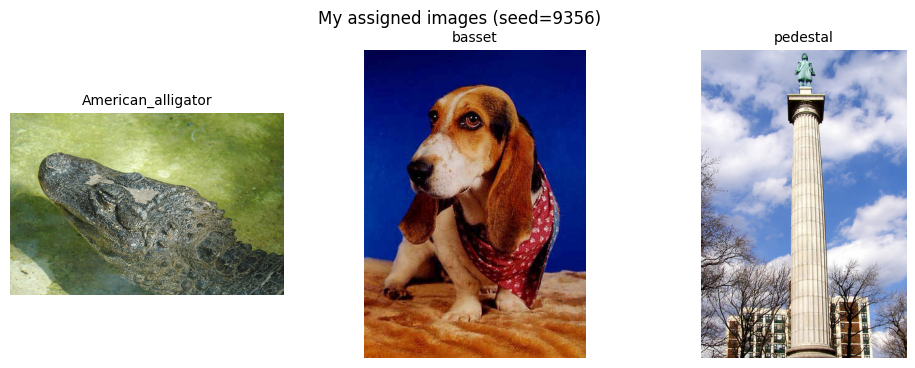

In [4]:
# 시드로 나만의 이미지 3장 배정받기
IMG_DIR = "imagenet-sample-images"
all_files = sorted(f for f in os.listdir(IMG_DIR) if f.upper().endswith(".JPEG"))
my_files = random.Random(SEED).sample(all_files, 3)

my_images = [Image.open(os.path.join(IMG_DIR, f)).convert("RGB") for f in my_files]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, name in zip(axes, my_images, my_files):
    ax.imshow(img); ax.axis("off")
    ax.set_title(name.split("_", 1)[-1].replace(".JPEG", ""), fontsize=10)
# 그래프 안 텍스트는 영문 사용 — Colab 기본 폰트에 한글이 없어 □로 깨집니다
plt.suptitle(f"My assigned images (seed={SEED})")
plt.show()


# 1. 필수 과제

## 1.1 사전학습 CNN 준비 — 모델은 내 이미지를 뭐라고 볼까?

ImageNet으로 학습된 **ResNet-18**을 불러와서, 배정받은 이미지 3장에 대한 **top-5 예측**을 확인합니다.
이 예측 결과가 이후 모든 문제의 출발점이 됩니다. *(이 단계는 코드가 거의 완성되어 있어요 — 주석 빈칸만 채우면 됩니다)*

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💬 주석 빈칸이란?</b><br>코드 중간의 <code># (빈칸 A) ...</code> 주석을 채우는 문제입니다. '내가 지금 어느 단계의 무엇을 하고 있는지'를 스스로 설명할 수 있어야 나중에 코드를 응용할 수 있기 때문에 넣었습니다. 한 줄이면 충분합니다!</div>

In [5]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).to(device).eval()   # (빈칸 A) .eval()을 호출하는 이유는? → BatchNorm 이 미니배치 통계 대신 학습 때 저장한 running mean/var 를 쓰도록 추론 모드로 고정 (Dropout 이 있으면 끄는 역할도 함)
categories = weights.meta["categories"]               # ImageNet 1000개 클래스 이름
preprocess = weights.transforms()                     # (빈칸 B) 이 전처리가 하는 일 두 가지는? → ① resize(256) + center crop(224)로 입력 크기 맞추기 ② [0,1] 텐서로 바꾼 뒤 ImageNet mean/std 로 정규화 (학습 때와 같은 입력 분포)

def predict_probs(img_pil):
    """PIL 이미지 → 1000개 클래스 확률 (torch.Tensor, shape [1000])"""
    x = preprocess(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():                             # (빈칸 C) 여기서 no_grad를 쓰는 이유는? → 예측만 하고 backward 는 안 하니까 계산 그래프를 만들지 않아 메모리·시간 절약
        logits = model(x)
    return F.softmax(logits, dim=1)[0].cpu()

for name, img in zip(my_files, my_images):
    probs = predict_probs(img)
    top5 = probs.topk(5)
    print(f"\n📷 {name}")
    for p, idx in zip(top5.values, top5.indices):
        print(f"   {categories[idx]:30s} {p*100:5.1f}%")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 98.3MB/s]



📷 n01698640_American_alligator.JPEG
   African crocodile               55.5%
   American alligator              44.2%
   terrapin                         0.0%
   Komodo dragon                    0.0%
   sea cucumber                     0.0%

📷 n02088238_basset.JPEG
   basset                          90.0%
   beagle                           5.1%
   Walker hound                     2.7%
   English foxhound                 1.3%
   bloodhound                       0.5%

📷 n03903868_pedestal.JPEG
   pedestal                        90.7%
   water tower                      7.2%
   mosque                           0.4%
   pole                             0.3%
   beacon                           0.3%


## 1.2 🔴 Grad-CAM 직접 구현 — 이 과제의 포인트

수업에서 배운 5단계 파이프라인을 그대로 코드로 옮깁니다. 라이브러리(`pytorch-grad-cam` 등)를 쓰지 않고
**hook으로 직접** 구현하는 것이 포인트입니다.

> **수업 복습** — ① Forward로 클래스 점수 $y^c$ 계산 → ② $y^c$를 마지막 conv의 feature map $A^k$까지 backward →
> ③ gradient를 공간 평균해 채널 가중치 $\alpha_k^c$ → ④ $\sum_k \alpha_k^c A^k$ 후 ReLU → ⑤ 입력 크기로 upsample

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 힌트</b><br>· hook은 '모델이 계산하는 중간 값을 몰래 저장하는 장치'입니다. forward hook은 활성값 A^k를, backward hook은 ∂y^c/∂A^k를 잡아둡니다 (둘 다 코드로 제공됨).<br>· <b>TODO 1</b>: gradient 텐서 shape은 [1, K, h, w]. 공간 축(h, w)에 대해 평균하면 α가 됩니다 → <code>mean(dim=?)</code><br>· <b>TODO 2</b>: α(shape [1,K,1,1])와 activations([1,K,h,w])를 곱해 채널 축으로 합한 뒤 ReLU → 수업의 2×2 손계산 예제와 같은 연산!<br>· 잘 됐는지 확인: 다음 셀의 시각화에서 히트맵이 물체 위에 얹혀야 정상입니다.</div>

In [6]:
class GradCAM:
    """수업의 5단계 파이프라인을 그대로 구현한 최소 Grad-CAM"""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None   # A^k  가 저장될 자리
        self.gradients = None     # ∂y^c/∂A^k 가 저장될 자리
        # hook 등록: forward/backward 때 중간값을 가로채 저장
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()          # shape [1, K, h, w]

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()    # shape [1, K, h, w]

    def __call__(self, x, class_idx=None):
        # ① Forward — 클래스 점수 계산
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        # ② Backward — 선택한 클래스 점수만 미분
        score = logits[0, class_idx]
        score.backward()

        # ③ 채널 가중치 α_k^c 계산
        # (빈칸 D) 이 줄이 수업 슬라이드의 어떤 수식에 해당하는지 쓰세요 → \alpha_k^c = \frac{1}{Z}\sum_i\sum_j \frac{\partial y^c}{\partial A_{ij}^k}  (gradient 의 global average pooling)
        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)         # [1, K, 1, 1] — 공간 축(h, w) 평균

        # ④ 가중합 + ReLU
        # (빈칸 E) ReLU를 마지막에 적용하는 이유는? → 클래스 c 점수를 올리는(양의 영향) 위치만 남기려고. 음수 쪽은 다른 클래스의 근거일 가능성이 커서 섞이면 위치 추정이 흐려짐
        cam = F.relu((alpha * self.activations).sum(dim=1))            # [1, h, w] — 채널 가중합 후 ReLU

        # ⑤ 정규화 + 입력 크기로 upsample (완성되어 있음)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(cam.unsqueeze(0), size=x.shape[-2:],
                            mode="bilinear", align_corners=False)
        return cam[0, 0].cpu().numpy(), class_idx

# 마지막 conv 블록(layer4의 마지막 BasicBlock)에 hook을 겁니다
gradcam = GradCAM(model, model.layer4[-1])
print("GradCAM 준비 완료")


GradCAM 준비 완료


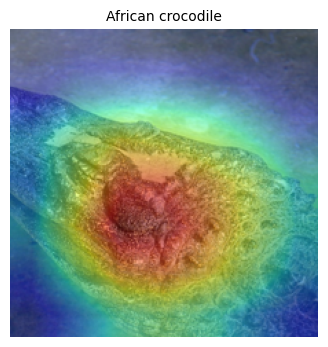

In [7]:
# 시각화 도우미 (완성 코드 — 그대로 실행)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

def to_numpy_img(x):
    """정규화된 텐서[3,H,W] → 화면 표시용 numpy[H,W,3]"""
    return (x.cpu() * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

def show_gradcam(img_pil, class_idx=None, ax=None, title=None):
    x = preprocess(img_pil).unsqueeze(0).to(device)
    cam, used_idx = gradcam(x, class_idx)
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(to_numpy_img(x[0])); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.axis("off"); ax.set_title(title or categories[used_idx], fontsize=10)
    return used_idx

# 동작 확인: 첫 번째 배정 이미지의 top-1 히트맵
show_gradcam(my_images[0])
plt.show()


## 1.3 실험 — 같은 이미지, 다른 클래스로 미분하면?

Grad-CAM의 매력은 **class-discriminative**, 즉 "어느 클래스 입장에서 보는가"를 우리가 고를 수 있다는 점이었죠
(수업의 Cat/Dog 그림). 내 이미지 3장 각각에 대해 **top-1 클래스 히트맵과 top-2 클래스 히트맵**을 나란히 그려 비교하세요.

**해야 할 일**
1. 아래 셀을 완성해 3장 × (원본 | top-1 CAM | top-2 CAM) 그리드를 그린다
2. 그림 아래 답안 셀에 해석을 쓴다 — *top-1과 top-2 히트맵이 다른 곳을 비추는 이미지가 있나요? 그 이유는 무엇일까요?
모델이 엉뚱한 곳(배경 등)을 보는 경우가 있다면 그것은 무엇을 시사하나요?*

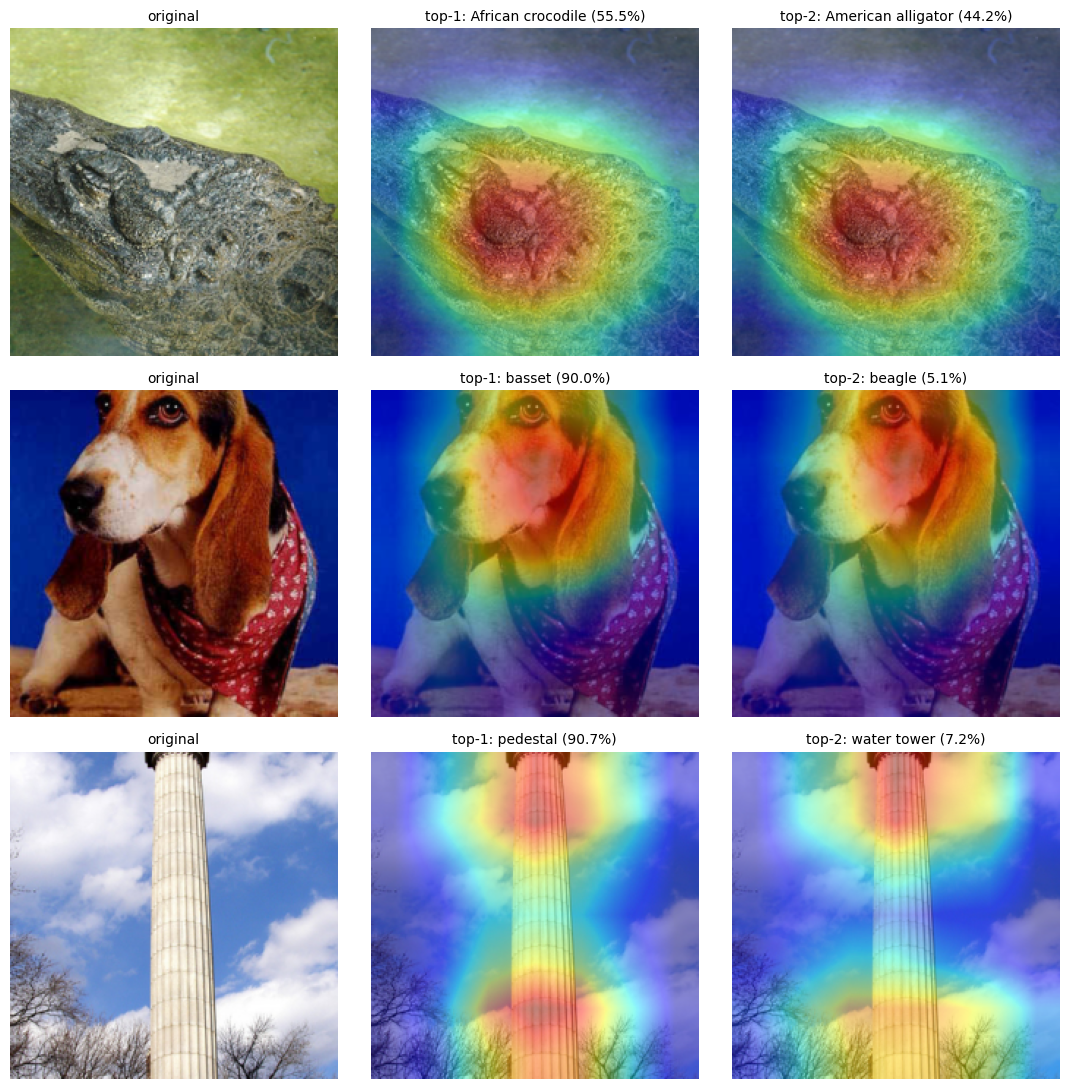

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, (name, img) in enumerate(zip(my_files, my_images)):
    probs = predict_probs(img)
    top2 = probs.topk(2).indices.tolist()

    x = preprocess(img).unsqueeze(0).to(device)
    axes[r, 0].imshow(to_numpy_img(x[0])); axes[r, 0].axis("off")
    axes[r, 0].set_title("original", fontsize=10)   # 그래프 안 텍스트는 영문 (Colab 한글 폰트 미지원)

    # TODO: top-1 클래스의 히트맵을 axes[r, 1]에,
    #       top-2 클래스의 히트맵을 axes[r, 2]에 그리세요 (show_gradcam 활용)
    # (빈칸 F) top-2 히트맵을 그릴 때 class_idx 인자에 무엇을 넣어야 하나요? → top2[1] (두 번째로 확률이 높은 클래스 인덱스 — 비워 두면 argmax 인 top-1 로 미분됨)
    show_gradcam(img, class_idx=top2[0], ax=axes[r, 1],
                 title=f"top-1: {categories[top2[0]]} ({probs[top2[0]].item()*100:.1f}%)")
    show_gradcam(img, class_idx=top2[1], ax=axes[r, 2],
                 title=f"top-2: {categories[top2[1]]} ({probs[top2[1]].item()*100:.1f}%)")

plt.tight_layout(); plt.show()


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.3 답안</b></div>

· top-1 vs top-2 히트맵 비교에서 발견한 것:

세 장 모두 top-1과 top-2 히트맵이 거의 같은 곳을 비췄다. 악어 사진은 African crocodile(55.5%)과 American alligator(44.2%) 둘 다 눈 위 튀어나온 부분을 중심으로 머리 쪽이 빨갛게 나왔고, 눈으로는 차이를 거의 찾지 못했다. 개 사진도 basset(90.0%)과 beagle(5.1%) 둘 다 얼굴과 귀를 봤다. 그나마 차이가 보인 건 기둥 사진의 pedestal(90.7%)과 water tower(7.2%)다. pedestal은 기둥 윗부분(장식 있는 머리 부분)과 아랫부분이 같이 빨갛게 나왔는데, water tower는 위쪽에 더 몰리고 아랫부분은 노란색으로 약해졌다. 급수탑은 꼭대기에 물탱크가 얹힌 구조라 위쪽을 더 보는 게 그럴듯하다.

· 그 차이/유사가 생긴 이유(모델 구조·클래스 관계 관점):

먼저 두 클래스가 생김새부터 비슷하다(악어 두 종, 사냥개 두 종). 구조적으로 보면 ResNet-18에서 Grad-CAM이 클래스마다 달라지는 부분은 마지막 fc 가중치뿐이다. layer4 뒤에 global average pooling과 fc 한 층만 있어서, 클래스 점수를 layer4 feature map으로 미분하면 채널 가중치가 그 클래스의 fc 가중치를 feature map 크기(7x7, 49칸)로 나눈 값이 된다. 클래스가 달라도 같은 feature map 512장을 fc 가중치로 다르게 섞을 뿐이니, 비슷한 클래스는 fc 가중치도 비슷하고 히트맵도 비슷해진다. 게다가 히트맵의 원래 해상도가 7x7이라 위치 차이를 세밀하게 보여 주기 어렵다. 같은 부위를 다른 근거로 쓰는 경우(악어 주둥이 모양 차이 같은 것)는 이 해상도에서는 드러나지 않는다.

· 배경 등 엉뚱한 곳을 보는 경우가 있었다면 그 의미:

크게 엉뚱한 곳을 본 경우는 없었지만, pedestal 사진에서 기둥 양옆 하늘과 아래쪽 나무까지 히트맵이 번졌다. 일부는 7x7을 224로 늘리면서 경계가 뭉개진 탓이겠지만, 하늘 배경이 야외에 높이 선 구조물이라는 판단에 맥락으로 쓰였을 수도 있다. 만약 모델이 물체보다 배경을 근거로 맞히는 거라면, 같은 물체가 실내나 다른 배경에 있을 때 틀릴 위험이 있다. 그리고 첫 사진은 파일 이름이 American alligator인데 top-1은 African crocodile(55.5%)이었다. 히트맵은 정확히 머리를 보고 있었으니, 올바른 곳을 보는 것과 맞게 예측하는 것은 별개라는 것도 확인했다.

## 1.4 LIME — 같은 이미지를 Perturbation으로 설명하면?

이번에는 **모델 내부를 전혀 모른 채** superpixel을 켜고 끄는 LIME으로 같은 이미지를 설명합니다.

**해야 할 일**
1. 아래 코드로 첫 번째 배정 이미지의 LIME 설명을 만든다 *(1~2분 걸립니다 — 수업에서 왜 느리다고 했는지 떠올려 보세요!)*
2. `num_features`를 **3 → 10**으로 바꿔 다시 실행하고 두 결과를 비교한다
3. **같은 조건으로 한 번 더** 실행해 결과가 달라지는지(불안정성) 관찰한다

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 파라미터 읽는 법</b><br><code>num_samples</code> = 만들 변형 샘플 수(= 모델에 질의하는 횟수), <code>num_features</code> = 설명에 남길 superpixel 조각 수 (수업 목적함수의 Ω(g) — 복잡도 제한에 해당)</div>

In [9]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

def batch_predict(images):
    """LIME이 부르는 예측 함수: numpy 이미지 배치 → 클래스 확률 배치"""
    batch = torch.stack([preprocess(Image.fromarray(im)) for im in images]).to(device)
    with torch.no_grad():
        logits = model(batch)
    return F.softmax(logits, dim=1).cpu().numpy()

target_img = np.array(my_images[0].resize((224, 224)))
explainer = lime_image.LimeImageExplainer(random_state=SEED)

explanation = explainer.explain_instance(
    target_img,
    batch_predict,        # LIME은 이 함수를 '질의'만 함 — model-agnostic의 실체!
    top_labels=1,
    num_samples=1000,     # 변형 샘플 1000개 = 추론 1000번
)
print("LIME 설명 생성 완료 — top 클래스:", categories[explanation.top_labels[0]])


  0%|          | 0/1000 [00:00<?, ?it/s]

LIME 설명 생성 완료 — top 클래스: American alligator


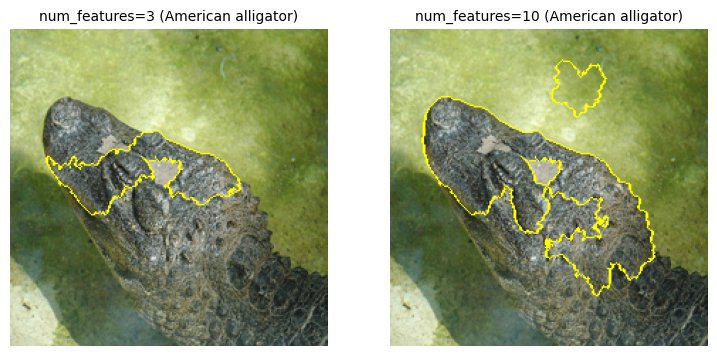

In [10]:
# num_features 를 3, 10 으로 바꿔 두 번 그려 비교하세요
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, k in zip(axes, [3, 10]):
    # TODO: explanation.get_image_and_mask(...)를 호출해
    #       positive_only=True, num_features=k, hide_rest=False 로 마스크를 얻고
    #       mark_boundaries(temp/255.0, mask) 를 ax.imshow 로 그리세요
    # (빈칸 G) num_features가 수업 목적함수의 어떤 항에 해당? → \Omega(g), 설명 모델 g 의 복잡도 제한 항 (쓸 수 있는 superpixel 수 K). 엄밀히는 이미 맞춘 g 에서 가중치 상위 k 개만 골라 보여주는 것
    temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=True,
                                                num_features=k, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis("off")
    ax.set_title(f"num_features={k} ({categories[explanation.top_labels[0]]})", fontsize=10)
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

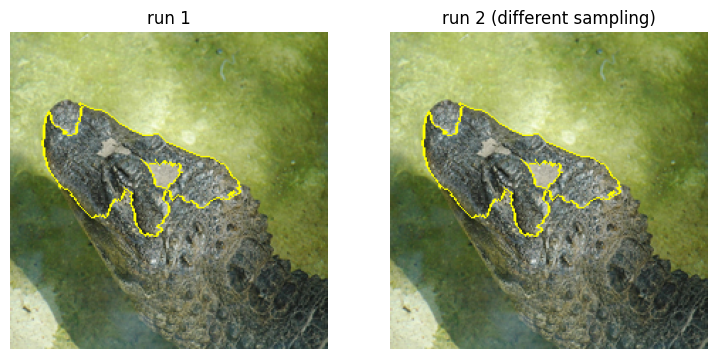

In [11]:
# 불안정성 실험: random_state를 바꿔 같은 설명을 한 번 더
explainer2 = lime_image.LimeImageExplainer(random_state=SEED + 1)
explanation2 = explainer2.explain_instance(target_img, batch_predict,
                                           top_labels=1, num_samples=1000)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (exp, t) in zip(axes, [(explanation, "run 1"), (explanation2, "run 2 (different sampling)")]):
    temp, mask = exp.get_image_and_mask(exp.top_labels[0], positive_only=True,
                                        num_features=5, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis("off"); ax.set_title(t)
plt.show()
# 두 실행의 결과가 완전히 같은가요? 다르다면 어느 정도 다른가요? → 아래 답안 셀에 기록


## 1.5 종합 비교 — Grad-CAM vs LIME (서술형)

1.3과 1.4의 결과를 옆에 놓고, 아래 표의 빈칸을 **본인의 실험 결과 근거**를 들어 채우세요.
"수업에서 배웠으니까"가 아니라 **"내 실험에서 이렇게 나왔으니까"**로 쓰는 것이 이 문제의 전부입니다.

| 비교 항목 | Grad-CAM (내 결과) | LIME (내 결과) |
|---|---|---|
| 걸린 시간 (체감) | 거의 바로 나왔다. forward 1번, backward 1번이면 끝난다 | 설명 한 번에 진행바 1,000칸이 다 찰 때까지 기다려야 했다. 변형 이미지 1,000장을 모델에 넣어야 해서(추론 1,000번) Grad-CAM보다 훨씬 오래 걸렸다 |
| 설명의 형태·해상도 | 연속값 히트맵이다. 원래 7x7을 224로 늘린 거라 뭉툭한 덩어리 모양이고 경계가 물체 윤곽과 맞지 않는다 | superpixel 단위로 켜진 영역이다. 경계가 실제 윤곽(악어 머리 테두리)을 따라가서 더 날카롭지만, 영역 안에서 어디가 더 중요한지는 안 보인다 |
| 재실행 시 안정성 | 같은 입력이면 매번 같은 결과다(계산에 무작위 요소가 없다) | random_state를 바꿔 다시 돌렸는데 top-5 superpixel 경계가 픽셀 단위로 완전히 같았다. 이번 이미지에서는 불안정성이 보이지 않았다 |
| 모델 내부 접근이 필요했나? | 필요했다. layer4에 hook을 걸어 activation과 gradient를 꺼내야 했다 | 필요 없었다. batch_predict로 확률만 받았다 |

<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.5 답안</b></div>

· 1.4 관찰(num_features, 재실행):

num_features=3이면 악어 눈두덩과 주둥이 윗부분 superpixel 세 개만 남았다. 10으로 늘리니 머리 대부분이 들어오면서 위쪽 물 배경 조각 하나도 같이 선택됐다. 순위가 낮은 조각으로 갈수록 근거라기보다 잡음에 가까운 영역이 섞인다는 뜻으로 읽었다. num_features는 설명을 얼마나 단순하게 보여 줄지 정하는 값인데, 크게 잡으면 오히려 설명을 믿기 어려워진다. 재실행 결과가 같았던 건 샘플 1,000개면 상위 5개 순위가 안 흔들릴 만큼 가중치 차이가 컸기 때문인 것 같다. 샘플 수를 줄이거나 하위 순위까지 보면 달라질 수 있어서 LIME이 안정적이라고 일반화하지는 않겠다.

· 두 기법의 차이가 생기는 근본 원인(Gradient vs Perturbation 축으로 설명):

Grad-CAM은 gradient 기반이라 모델 안에서 이 feature map이 클래스 점수를 얼마나 올리는지를 미분으로 한 번에 구한다. 그래서 빠르고 결과가 결정적이지만, 내부 층에 접근해야 하고 해상도가 마지막 conv 층 크기(7x7)에 묶인다. LIME은 perturbation 기반이라 모델 내부는 안 보고, 입력 조각을 껐다 켜면서 출력이 어떻게 바뀌는지만 본 다음 그 근처를 선형 모델로 근사한다. 질의가 많이 필요해서 느리고, 샘플링에 따라 결과가 바뀔 수 있고, 설명 단위가 superpixel 분할 방식에 좌우된다. 대신 경계는 이미지 윤곽을 따라간다.

하나 덧붙이면, 이번 비교에서 두 방법은 사실 조금 다른 입력을 설명했다. Grad-CAM은 preprocess(resize 256 후 center crop 224)를 거친 이미지라 top-1이 African crocodile이었고, LIME은 원본을 224x224로 그대로 줄인 이미지라 top 클래스가 American alligator였다. 두 클래스 확률이 55.5% 대 44.2%로 거의 반반이라 crop 차이만으로 1등이 바뀐 것이다. 사진에 담긴 범위도 다르니(LIME 쪽은 머리 전체가 보인다) 두 설명을 1:1로 겹쳐 보면 안 된다.

· 만약 ①모델 코드를 볼 수 없는 외부 API ②내가 학습시킨 CNN, 각각의 상황에서 어떤 기법을 쓸지와 이유:

① 외부 API라면 내부에 접근할 수 없으니 LIME처럼 입력과 출력만 쓰는 방법밖에 없다. 다만 질의 횟수만큼 API 비용과 호출 제한이 걸려서 num_samples를 무작정 늘릴 수 없다. 결과도 샘플링에 따라 바뀔 수 있으니 시드를 바꿔 몇 번 돌려 보고 공통으로 나오는 영역만 믿겠다.

② 내가 학습시킨 CNN이라면 Grad-CAM을 쓰겠다. 마지막 conv 층에 hook만 걸면 되고, 빠르고 결정적이라 데이터 전체에 돌리면서 배경을 보는 것 같은 이상한 근거를 찾기 좋다. 경계가 뭉툭하니 정확한 부위가 궁금한 몇 장만 LIME으로 보충하겠다. 2.2의 sanity check를 통과했다는 점도 Grad-CAM 결과를 믿을 근거가 된다.

# 2. 심화 과제 (선택 — 둘 중 하나만 해도 됩니다)

## 2.1 SHAP — 표 데이터에서 Local ↔ Global 오가기

이미지에서 벗어나 SHAP이 가장 빛나는 **표 데이터 + 트리 모델** 조합을 경험합니다.
캘리포니아 주택 가격 데이터로 RandomForest를 학습하고 **TreeSHAP**으로 설명합니다.

**해야 할 일** — ① beeswarm(=summary) plot으로 **전역(Global)** 중요도를 읽고 ② waterfall plot으로 **개별 예측(Local)** 하나를 분해한 뒤
③ 수업에서 배운 **Local Accuracy**(기여도 합 = 예측값)를 코드로 직접 검증하세요.

R^2 (test): 0.765


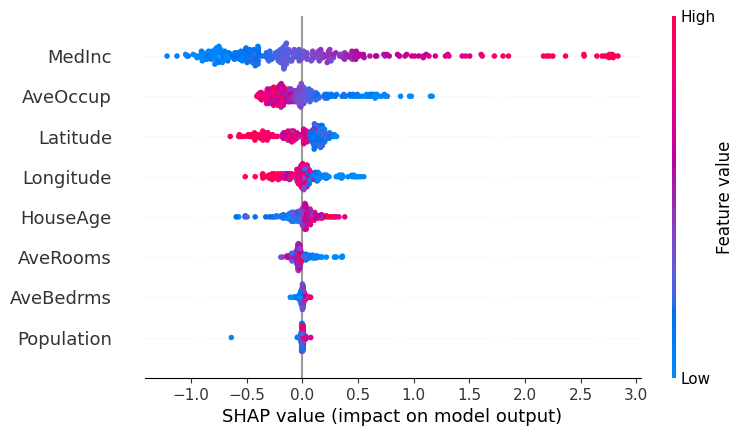

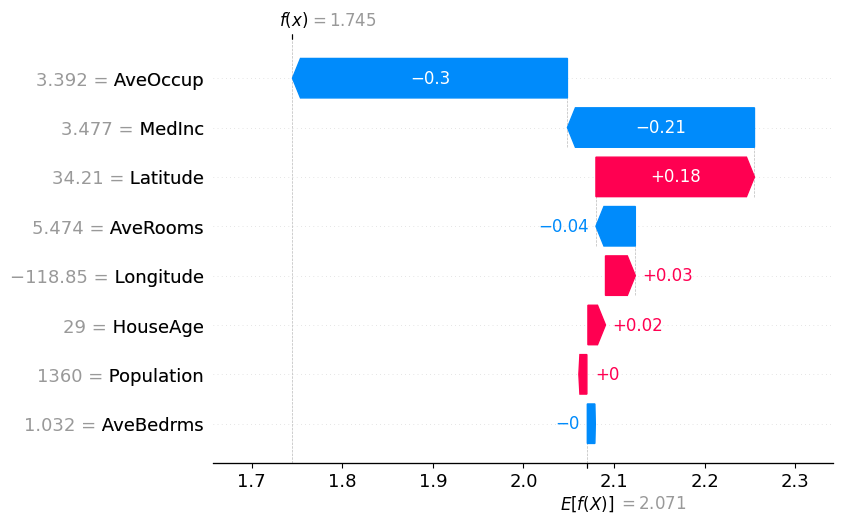

rf.predict(첫 샘플)        = 1.745034
base_value + sum(SHAP 값) = 2.070533 + -0.325499 = 1.745034
차이 = 2.22e-15  →  Local Accuracy 성립: True


In [12]:
import shap
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

rf = RandomForestRegressor(n_estimators=100, max_depth=8,
                           random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
print("R^2 (test):", round(rf.score(X_te, y_te), 3))

# TreeSHAP: 트리 구조를 이용해 정확한 Shapley 값을 빠르게 계산
explainer = shap.TreeExplainer(rf)
sv = explainer(X_te.iloc[:300])

shap.plots.beeswarm(sv)          # Global: 전체 경향
shap.plots.waterfall(sv[0])      # Local: 첫 번째 집 한 채의 분해

# TODO: Local Accuracy 검증 —
#   sv[0].values 의 합 + sv[0].base_values 가 rf.predict(첫 샘플) 과 (거의) 같은지 확인
# (빈칸 H) base_values는 수업 force plot 그림의 무엇에 해당? → base value = E[f(X)], 배경 데이터 전체에 대한 모델의 평균 예측 (force plot 에서 기여도 화살표들이 출발하는 기준점)
pred0  = float(rf.predict(X_te.iloc[[0]])[0])
base0  = float(np.asarray(sv[0].base_values).reshape(-1)[0])
recon0 = base0 + float(sv[0].values.sum())
print(f"rf.predict(첫 샘플)        = {pred0:.6f}")
print(f"base_value + sum(SHAP 값) = {base0:.6f} + {recon0 - base0:.6f} = {recon0:.6f}")
print(f"차이 = {abs(pred0 - recon0):.2e}  →  Local Accuracy 성립: {np.isclose(pred0, recon0, rtol=1e-4)}")


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 2.1 답안</b></div>

· beeswarm에서 가장 중요한 feature 2개와, 그 값이 클 때 집값을 올리는지/내리는지:

1위는 MedInc(지역 중위 소득)다. 값이 클수록(빨간 점) SHAP이 양수 쪽으로 멀리 가서 최대 +2.8 근처까지 집값을 올리고, 낮은 값(파란 점)은 -1 근처까지 내린다. 2위는 AveOccup(가구당 평균 거주 인원)인데 방향이 반대다. 값이 클수록 SHAP이 음수라 집값을 내리고, 작을수록(파란 점) 최대 +1.1 정도 올린다. 한 집에 사람이 많이 사는 동네일수록 집값이 낮게 예측된다는 뜻이다.

· waterfall의 첫 샘플: 예측을 가장 크게 움직인 feature와 방향:

기준값 2.071에서 출발해 예측값 1.745(약 17만 4,500달러)로 내려왔다. 가장 크게 움직인 건 AveOccup(3.392)으로 -0.30이고, 다음은 MedInc(3.477)로 -0.21이다. 반대로 Latitude(34.21)는 +0.18로 예측을 올렸다. 위도 34 근처면 남부 캘리포니아라 위치가 값을 올린 것으로 보인다. 결국 가구당 인원이 많고 소득이 높지 않은 쪽이라 평균보다 낮게 예측됐다.

· Local Accuracy 검증 결과:

base_value 2.070533에 SHAP 값 합 -0.325499를 더하면 1.745034고, rf.predict 값 1.745034와의 차이는 2.22e-15였다. 부동소수점 오차 수준이니 기준값에 각 feature의 SHAP 값을 전부 더하면 예측값이 된다는 성질이 그대로 성립했다. TreeSHAP은 트리 구조를 이용해 Shapley 값을 근사 없이 계산하니 이렇게 딱 맞는 게 당연하다.

## 2.2 Sanity Check — 이 설명, 정말 모델을 보고 있나?

수업 3부에서 "설명 기법 자체도 검증 대상"이라고 했습니다 (Adebayo et al., 2018).
그 검증을 직접 해봅니다: **모델의 뒷부분 가중치를 랜덤으로 망가뜨렸을 때, Grad-CAM 히트맵이 함께 망가지는지** 확인합니다.

> 만약 모델을 망가뜨렸는데도 히트맵이 그대로라면 → 그 히트맵은 모델의 판단이 아니라
> 이미지의 윤곽선을 그리고 있었다는 뜻 (= 설명으로서 실격!)

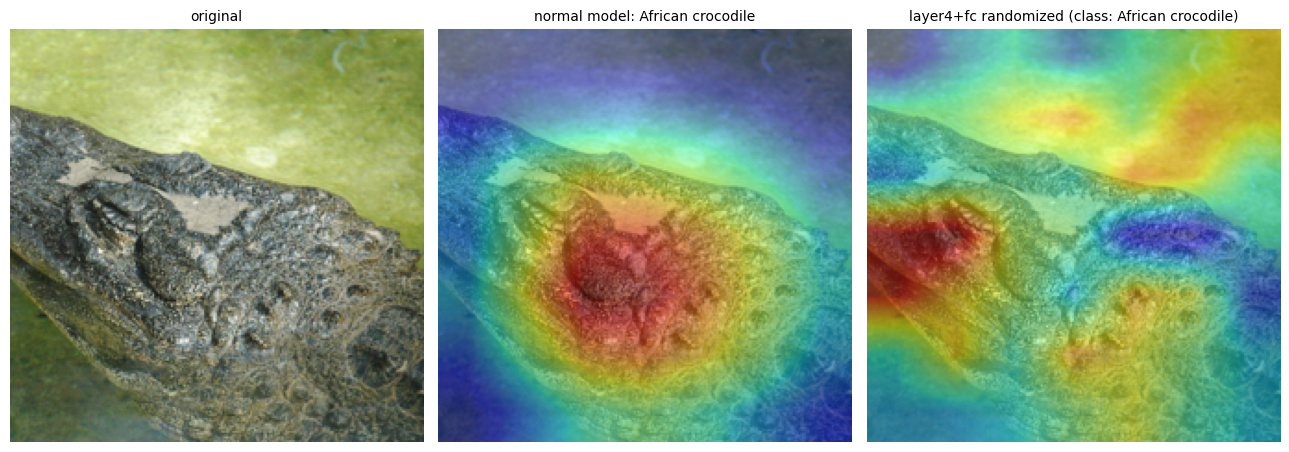

망가진 모델의 top-1 예측: white stork
정상 vs 망가진 히트맵 Spearman 순위상관 = 0.222  (1 에 가까울수록 '안 바뀜' = 설명으로서 의심)


In [13]:
# 모델 복사 후 layer4와 fc의 가중치를 랜덤화
model_broken = copy.deepcopy(model)
for module in [model_broken.layer4, model_broken.fc]:
    for p in module.parameters():
        torch.nn.init.normal_(p, std=0.02)
model_broken.eval()

gradcam_broken = GradCAM(model_broken, model_broken.layer4[-1])

# TODO: 첫 번째 배정 이미지에 대해
#   ① 정상 모델의 히트맵 ② 망가진 모델의 히트맵 을 나란히 그리고 비교하세요
# (빈칸 I) 이 실험에서 히트맵이 '달라져야' 좋은 설명 기법인 이유 → 설명은 '이 모델이 무엇을 근거로 판단했나'를 보여줘야 하므로 가중치가 망가지면 설명도 바뀌어야 함. 그대로라면 모델과 무관하게 이미지 윤곽만 그리는 edge detector 와 다를 게 없음 (model parameter randomization test)
from scipy.stats import spearmanr

x0 = preprocess(my_images[0]).unsqueeze(0).to(device)
cam_ok, cls_ok = gradcam(x0)                              # ① 정상 모델: top-1 클래스로 미분
cam_br, _      = gradcam_broken(x0, class_idx=cls_ok)     # ② 망가진 모델: 같은 클래스로 미분 (같은 조건 비교)
with torch.no_grad():
    cls_br = model_broken(x0).argmax(1).item()            # 참고: 망가진 모델은 뭐라고 예측하나

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax in axes:
    ax.imshow(to_numpy_img(x0[0])); ax.axis("off")
axes[0].set_title("original", fontsize=10)
axes[1].imshow(cam_ok, cmap="jet", alpha=0.45); axes[1].set_title(f"normal model: {categories[cls_ok]}", fontsize=10)
axes[2].imshow(cam_br, cmap="jet", alpha=0.45); axes[2].set_title(f"layer4+fc randomized (class: {categories[cls_ok]})", fontsize=10)
plt.tight_layout(); plt.show()

rho = spearmanr(cam_ok.ravel(), cam_br.ravel()).correlation   # Adebayo et al. (2018) 이 쓴 순위 상관
print("망가진 모델의 top-1 예측:", categories[cls_br])
if np.isnan(rho):
    print("망가진 모델의 히트맵이 상수(전부 0)라 상관 계산 불가 → 정상 히트맵과 완전히 다름")
else:
    print(f"정상 vs 망가진 히트맵 Spearman 순위상관 = {rho:.3f}  (1 에 가까울수록 '안 바뀜' = 설명으로서 의심)")


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 2.2 해석</b></div>

망가진 모델의 히트맵은 정상 모델과 완전히 달랐다. 정상 모델(African crocodile)은 눈두덩을 중심으로 머리 부분이 빨갛게 나왔다. 반면 layer4와 fc를 무작위로 바꾼 모델은 같은 클래스로 미분해도 왼쪽 주둥이 쪽과 오른쪽 위 물 배경이 밝게 나왔고, 정상 모델이 가장 강하게 본 눈 부분은 오히려 약했다. 두 히트맵의 Spearman 순위상관은 0.222로 낮았고, 망가진 모델은 이 사진을 white stork로 예측했다.

모델이 망가지니 설명도 같이 망가졌으니, 적어도 이 이미지에서 Grad-CAM은 이미지 윤곽만 그리는 게 아니라 모델 가중치를 실제로 반영하고 있다.

상관이 0이 아니라 0.222 남은 건 layer1~layer3는 그대로라 그 층들이 만든 저수준 특징(질감, 경계)이 layer4 activation에 아직 섞여 있기 때문으로 보인다. 다만 이미지 한 장, 층 조합 하나만 본 결과다. Adebayo et al.처럼 위쪽 층부터 하나씩 무작위로 바꿔 가며 상관이 어떻게 떨어지는지까지 봐야 확실히 말할 수 있다.

# 3. 생성형 AI 활용 기록 (⚠️ 필수 제출)

<div style="background:#FEF2F2;border-left:6px solid #B91C1C;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B91C1C">반드시 작성해 주세요</b><br>이 셀이 비어 있으면 감점입니다. AI를 안 썼다면 '사용하지 않음'이라고 쓰면 됩니다. 솔직한 기록은 감점 사유가 아니며, 오히려 어떻게 도구를 썼는지가 평가 대상입니다.</div>

**작성 양식:**

### ① 핵심 대화 내역 붙여넣기
```
 Grad-CAM에서 register_backward_hook 말고 register_full_backward_hook을 써야 하는 이유가 뭐야?
 답 : 결론: 옛 register_backward_hook은 모듈 전체가 아니라 모듈 forward 안의 마지막 autograd 연산 하나에 걸려서, 모듈이 연산 여러 개로 이루어져 있으면 grad_input/grad_output이 실제 모듈의 입출력 gradient가 아닐 수 있어. register_full_backward_hook은 모듈의 진짜 입력과 출력 기준으로 gradient를 넘겨줘. 그래서 deprecated됐고 full 쪽을 쓰라고 하는 거야.

옛 hook이 틀리는 원리

옛 방식은 모듈 출력 텐서의 grad_fn, 즉 마지막으로 실행된 연산 노드에 hook을 붙여. 모듈이 nn.Conv2d처럼 연산 하나면 문제가 없어. 그런데 ResNet Bottleneck처럼 forward가 conv → bn → relu → … → out += identity → relu로 끝나는 블록이면 hook은 마지막 ReLU에 붙어. 이때 grad_input은 블록 입력 $x$에 대한 $\partial L/\partial x$가 아니라 마지막 ReLU 입력에 대한 gradient가 돼. 출력이 tuple이거나 forward가 입력을 그대로 반환하는 등 구조가 특이하면 hook이 엉뚱한 값을 주거나 아예 안 불리기도 해.

Grad-CAM 입장에서 보면, 필요한 건 target layer 출력 $A^k$에 대한 $\partial y^c/\partial A^k$이고 그걸로

$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$$

를 구하는 거잖아. grad_output만 쓰면 옛 hook으로도 우연히 맞는 경우가 많아. 하지만 layer4 같은 Sequential/블록 단위로 hook을 걸면 어떤 값이 들어오는지 보장이 없어서, 조용히 틀린 CAM이 나올 수 있다는 게 핵심 위험이야.

full hook의 원리와 주의점

register_full_backward_hook은 forward 때 모듈의 입력과 출력을 identity autograd Function(BackwardHookFunction)으로 감싸. 그래서 내부에 연산이 몇 개든 모듈 경계에서의 gradient를 정확히 잡아.

다만 Grad-CAM에서 자주 터지는 함정이 하나 있어. hook 건 모듈의 출력을 바로 다음 레이어가 in-place로 수정하면 에러가 나. 예를 들어 VGG features에서 conv 다음이 ReLU(inplace=True)인 경우, “Output 0 of BackwardHookFunctionBackward is a view and is being modified inplace” 같은 RuntimeError가 떠. 이럴 땐 해당 ReLU를 inplace=False로 바꾸거나, hook 위치를 ReLU 쪽으로 옮기면 돼.

실무에서 더 흔한 방법

사실 모듈 backward hook을 아예 안 쓰는 게 제일 깔끔해. forward hook에서 출력 텐서를 잡고, 그 텐서에 tensor.register_hook으로 gradient를 받는 방식이야. pytorch-grad-cam 라이브러리도 이 방식을 써.

python
def fwd_hook(m, inp, out):
    self.activations = out.detach()
    out.register_hook(lambda g: setattr(self, "gradients", g.detach()))

target_layer.register_forward_hook(fwd_hook)

텐서 단위라서 모듈 내부 구조에 영향을 안 받고, in-place 문제도 상대적으로 덜 생겨.
```

### ② AI 답변을 그대로 쓰지 않고 직접 판단/수정한 부분
- 없습니다. 질문을 애초에 많이 안해서,,


# 4. 회고

한 학기 뒤의 나에게 남기는 메모라고 생각하고 가볍게 적어 주세요.

- **가장 신기했던 결과** 하나: 가장 신기했던 건 첫 번째 사진이었다. 파일 이름은 American alligator인데 Grad-CAM 쪽에서는 top-1이 African crocodile(55.5%)이고 American alligator는 44.2%로 2등이었다. 그런데 LIME에서는 1등이 American alligator로 나왔고, 따져 보니 LIME은 center crop 없이 원본을 224x224로 줄인 이미지를 써서 전처리 차이만으로 1등이 뒤집힌 거였다. 같은 모델이라도 입력을 어떻게 자르느냐에 따라 답이 바뀔 수 있다는 건 기억해 두자.
- 수업 내용 중 과제를 하며 **비로소 이해된 것**: Grad-CAM 채널 가중치가 기울기 평균이라는 건 수업에서 식으로만 봤는데, 세 장 모두 top-1과 top-2 히트맵이 거의 같은 곳을 비추는 걸 보고 나서야 그 의미가 와닿았다. ResNet-18은 layer4 뒤에 평균 풀링과 fc 한 층밖에 없어서 채널 가중치가 결국 fc 가중치를 feature map 크기(7x7)로 나눈 값이 되고, 그래서 비슷한 클래스끼리는 히트맵도 비슷해질 수밖에 없다. SHAP 값을 다 더하면 예측값이 된다는 성질도 말로만 알았는데, 기준값 2.070533에 SHAP 값 합 -0.325499를 더한 게 예측값 1.745034와 2.22e-15 차이로 맞는 걸 직접 확인하니 확실히 이해됐다.

---
<div style="text-align:center;opacity:.75">수고했습니다! 🎉 — 모든 셀의 실행 결과가 남아 있는지 확인한 뒤 .ipynb로 제출해 주세요</div>